In [1]:
import numpyro
numpyro.set_host_device_count(4)  # run the 4 MCMC chains in parallel; must happen before JAX starts
import jax
import jax.numpy as jnp
jax.config.update("jax_enable_x64", True)  # double precision: we invert covariance matrices below

import numpy as np
import matplotlib.pyplot as plt
import corner
import numpyro.distributions as dist
from numpyro import infer
from numpyro.diagnostics import effective_sample_size

plt.style.use("bayesian_stats_course_tools.light")

# Week 11 Exercises: fitting the hyperparameters of Bayesian linear regression

In the weight-space explorer, the posterior over the weights is always computed for **fixed** hyperparameters $\sigma_w$ and $\beta$: whatever the sliders say. Here we treat them as unknowns and sample them, keeping the number of basis functions fixed at $M = 20$ and the noise level known, $\sigma_n = 0.15$.

The model, in the notation of the lecture (Rasmussen & Williams; $\Phi$ has one **column** $\phi(x_i)$ per data point):

$$f(x) = \sum_{j=0}^{M-1} w_j P_j(x) = \phi(x)^\top w, \qquad y = \Phi^\top w + \varepsilon, \qquad \varepsilon \sim \mathcal N_\varepsilon(0, \sigma_n^2 I)$$

$$w \sim \mathcal N_w\big(0, \Sigma_p\big), \qquad (\Sigma_p)_{jj} = \sigma_w^2\,(j+1)^{-\beta}$$

$$\ln \sigma_w \sim \mathcal U(\ln 0.05, \ln 5), \qquad \beta \sim \mathcal U(0, 6)$$

The prior ranges are the same as the explorer's sliders, so any posterior sample is a setting you can dial into the explorer.

**Data.** The files in `../lectures/data/gp_legendre/` are *identical* to what the explorer generates (seed 7, $\sigma_{\rm true} = 0.15$):

| file | explorer settings |
|---|---|
| `sin3x_n15.txt` | Truth sin(3x), $n = 15$ (the explorer's default) |
| `chirp_n40.txt` | Truth Chirp sin(6x²), $n = 40$ |

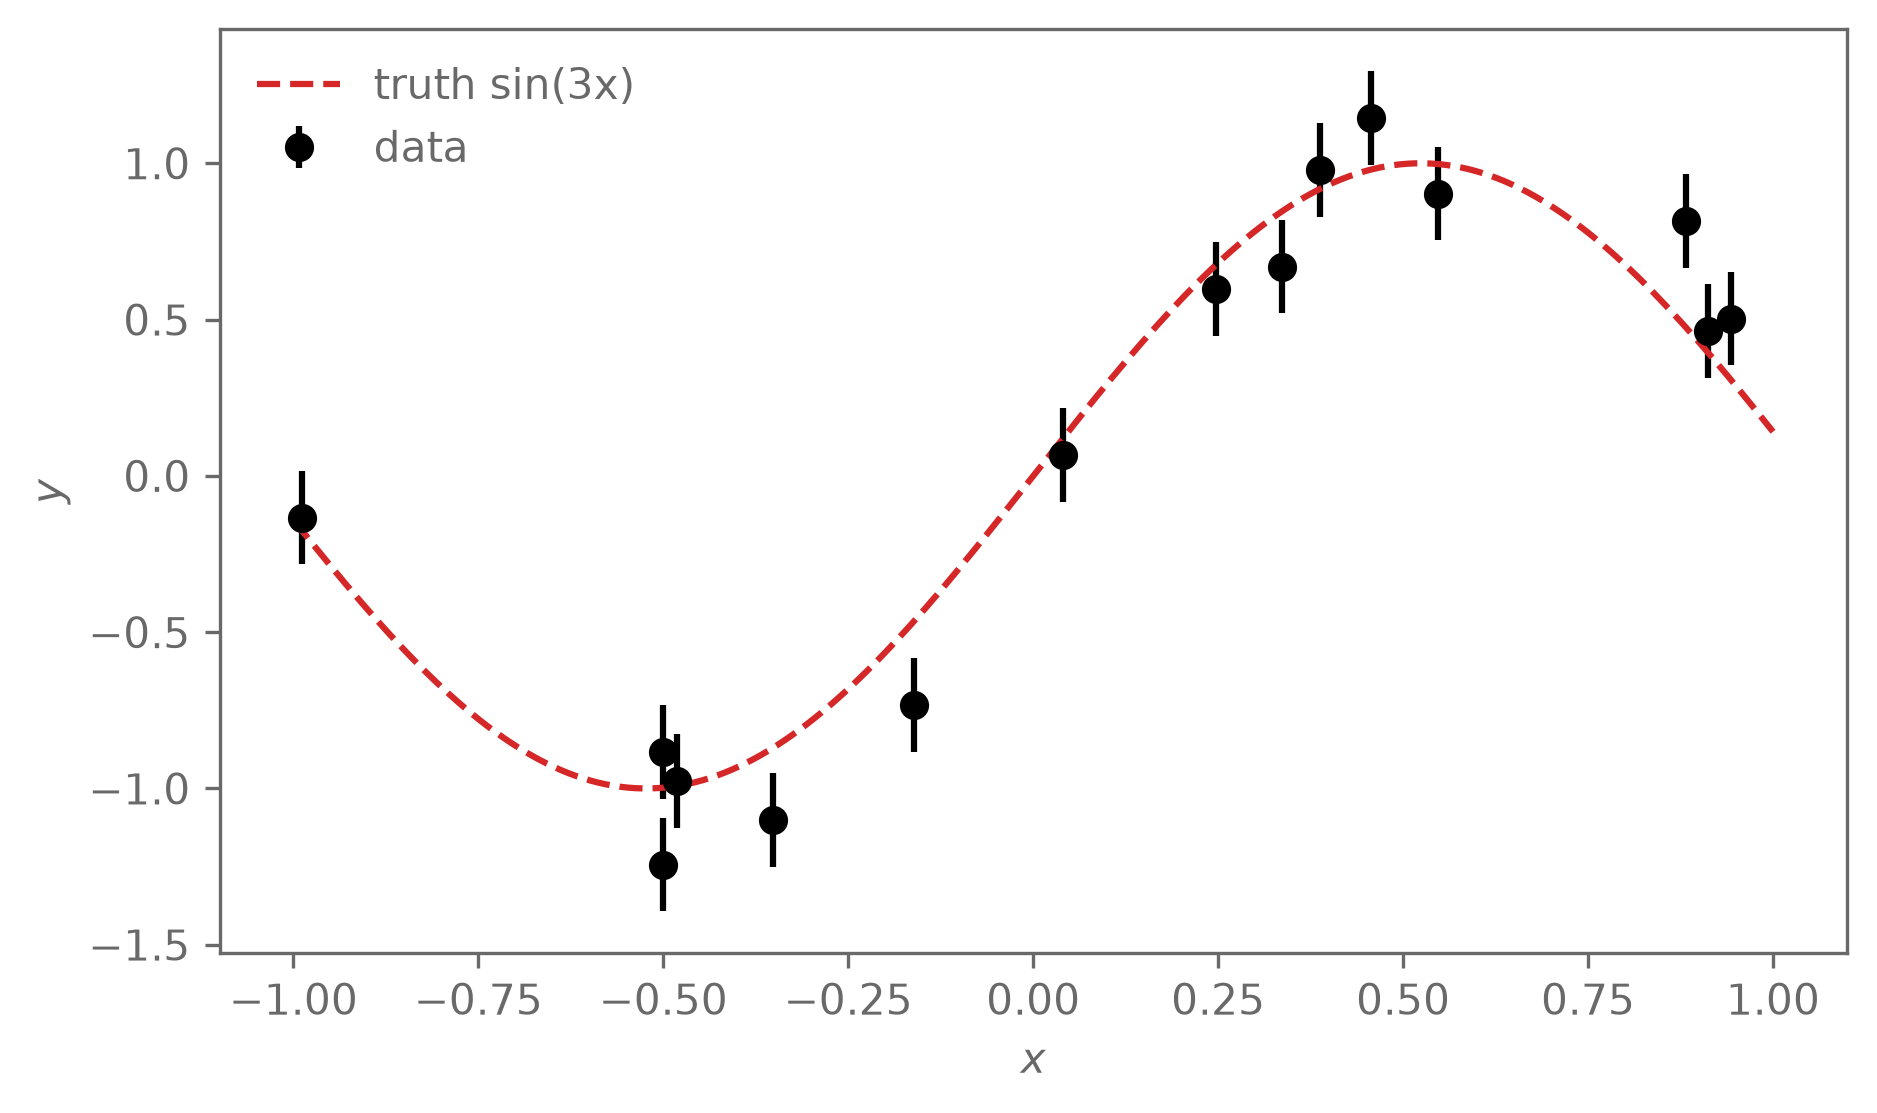

In [2]:
# Notation
#   n_basis    number of Legendre basis functions M (fixed at 20)
#   n_data     number of data points
#   n_test     number of x positions we predict at
#   n_samples  number of posterior samples (all chains together)
N_BASIS = 20
SIGMA_NOISE = 0.15                                  # sigma_n, treated as known
LOG_SIGMA_W_RANGE = (np.log(0.05), np.log(5.0))     # prior range of ln(sigma_w)
BETA_RANGE = (0.0, 6.0)                             # prior range of beta
DATA_DIRECTORY = "../lectures/data/gp_legendre"

# load the default data (15 noisy points of sin(3x)) and a grid of x values to predict at
x_data, y_data = np.loadtxt(f"{DATA_DIRECTORY}/sin3x_n15.txt", unpack=True)  # each (n_data,)
x_test = np.linspace(-1, 1, 200)                                              # (n_test,)

# plot the data and the true function
plt.errorbar(x_data, y_data, SIGMA_NOISE, fmt="o", color="k", label="data")
plt.plot(x_test, np.sin(3 * x_test), "--", color="C3", label="truth sin(3x)")
plt.xlabel("$x$"); plt.ylabel("$y$"); plt.legend();

In [3]:
def legendre_features(positions, n_basis):
    """Feature matrix Phi with one COLUMN per input (Rasmussen & Williams convention).

    positions: (n_points,) -> returns (n_basis, n_points); row j is P_j(x). A scalar gives (n_basis,).
    Uses the recursion (j+1) P_{j+1} = (2j+1) x P_j - j P_{j-1}.
    """
    # start from P_0 = 1 and P_1 = x, then build each higher degree from the two below it
    rows = [jnp.ones_like(positions), positions]
    for degree in range(1, n_basis - 1):
        rows.append(((2 * degree + 1) * positions * rows[degree] - degree * rows[degree - 1]) / (degree + 1))
    return jnp.stack(rows[:n_basis])


def prior_variances(sigma_w, beta, n_basis):
    """Diagonal of Sigma_p: (Sigma_p)_jj = sigma_w^2 (j+1)^(-beta). Shape (n_basis,)."""
    return sigma_w**2 * jnp.arange(1, n_basis + 1) ** (-beta)


def sample_hyperparameters():
    """Priors on sigma_w (log-uniform) and beta (uniform): the explorer's slider ranges."""
    # sample ln(sigma_w), so its prior is log-uniform; record sigma_w itself as a deterministic
    log_sigma_w = numpyro.sample("log_sigma_w", dist.Uniform(*LOG_SIGMA_W_RANGE))
    beta = numpyro.sample("beta", dist.Uniform(*BETA_RANGE))
    sigma_w = numpyro.deterministic("sigma_w", jnp.exp(log_sigma_w))
    return sigma_w, beta


def run_nuts(model, *model_args, target_accept=0.8, n_warmup=1000, n_samples_per_chain=1000, seed=0):
    """Run 4 NUTS chains; print the number of divergences and, if the model has one, the effective sample size (ESS) of beta."""
    # set up and run 4 NUTS chains, keeping track of which transitions diverged
    mcmc = infer.MCMC(infer.NUTS(model, target_accept_prob=target_accept), num_warmup=n_warmup,
                      num_samples=n_samples_per_chain, num_chains=4, progress_bar=False)
    mcmc.run(jax.random.key(seed), *model_args, extra_fields=("diverging",))
    # count the divergences, and compute the effective sample size of beta if the model has one
    n_divergent = int(mcmc.get_extra_fields()["diverging"].sum())
    samples_by_chain = mcmc.get_samples(group_by_chain=True)
    if "beta" in samples_by_chain:
        ess_beta = float(effective_sample_size(np.asarray(samples_by_chain["beta"])))
        print(f"divergences: {n_divergent},  ESS(beta): {ess_beta:.0f}")
    else:
        print(f"divergences: {n_divergent}")
    return mcmc


def plot_hyperparameter_posteriors(sample_sets, labels):
    """Overlay corner plots of (sigma_w, beta) for several runs. sample_sets: list of mcmc.get_samples()."""
    # draw each run's corner plot on top of the previous one, in a new color
    figure = None
    for index, (samples, label) in enumerate(zip(sample_sets, labels)):
        points = np.column_stack([np.log10(samples["sigma_w"]), samples["beta"]])
        figure = corner.corner(points, fig=figure, color=f"C{index}", bins=30, smooth=1.0,
                               labels=[r"$\log_{10}\sigma_w$", r"$\beta$"],
                               range=[(np.log10(0.05), np.log10(5.0)), BETA_RANGE],
                               plot_datapoints=False, plot_density=False, hist_kwargs={"density": True})
    # one legend entry per run
    figure.legend([plt.Line2D([], [], color=f"C{index}") for index in range(len(labels))], labels, loc="upper right")
    return figure

In [4]:
# Phi depends only on the inputs, so compute it once here rather than inside the models:
# a numpyro model is re-evaluated at every step of the sampler.
features = legendre_features(x_data, N_BASIS)        # Phi:   (n_basis, n_data)
features_test = legendre_features(x_test, N_BASIS)   # Phi_*: (n_basis, n_test)

# Exercise 1: sampling $\sigma_w$ and $\beta$ with $M = 20$ fixed

## Part A: weight space

Sample the weights and the hyperparameters **jointly**. This is a hierarchical model: the hyperparameters set the prior width of every weight.

$$w \sim \mathcal N_w\big(0, \Sigma_p(\sigma_w, \beta)\big), \qquad y \sim \mathcal N_y\big(\Phi^\top w,\ \sigma_n^2 I\big)$$

1. Complete `centered_model` below. It takes the precomputed feature matrix `features` ($\Phi$).
2. Run it with `run_nuts(centered_model, features, y_data)`. How many divergences do you get?
3. Plot the posterior of $(\sigma_w, \beta)$ with `plot_hyperparameter_posteriors`. Take the posterior medians of $\sigma_w$ and $\beta$ (`np.median`) and put them into the weight-space explorer (Truth sin(3x), $n = 15$, $M = 20$, $\sigma_n = 0.15$). Does the explorer's posterior look like a good fit?
4. Plot the **model posterior predictive** (the function $f$, no noise) with **the recipe** (slide "Predictions: the recipe"): for a few hundred posterior samples $w^{(s)}$, evaluate $f_*^{(s)} = \Phi_*^\top w^{(s)}$ with `features_test`, and plot the draws (or their mean and a band) together with the data.
5. **The weights.** Remake the *Weights* panel of the weight-space explorer from your samples: plot the posterior of each weight $w_j$ against its degree $j$ with `plt.violinplot`. If you have time, add the prior on the weights to the same plot, using the posterior on $(\sigma_w, \beta)$: for each posterior sample, draw $w_j \sim \mathcal N(0, s_j^2)$ with $s_j^2 = \sigma_w^2 (j+1)^{-\beta}$ (`prior_variances`). Which weights do the data pin down, and which are still set by the prior?

In [ ]:
def centered_model(features, y_data):
    sigma_w, beta = sample_hyperparameters()
    ...

In [ ]:
# TODO: run the sampler, then plot the (sigma_w, beta) posterior

In [ ]:
# TODO: model posterior predictive with the recipe

In [ ]:
# TODO: violin plot of the posterior on the weights (and of the prior, using the posterior on sigma_w and beta)

## Part B: integrate out the weights

The weights can be integrated out analytically (slide "Evidence"):

$$p(y \mid X, \sigma_w, \beta) = \mathcal N_y\big(0,\ C\big), \qquad C = \Phi^\top \Sigma_p \Phi + \sigma_n^2 I.$$

Now the sampler only sees the two hyperparameters.

1. Complete `marginal_model`: build $C$ yourself and use `dist.MultivariateNormal` as the likelihood.
2. Record the **model predictions** inside the model with `numpyro.deterministic`. They are not sampled: for fixed $(\sigma_w, \beta)$ the posterior over the weights is Gaussian, $\mathcal N_w(\mu_w, \Sigma_w)$ (slide "Posterior over the weights"), so the prediction at `x_test` is Gaussian too, with mean $\Phi_*^\top \mu_w$ and variance $\operatorname{diag}(\Phi_*^\top \Sigma_w \Phi_*)$ (slide "Predictions: closed form").
3. Sample it and compare the $(\sigma_w, \beta)$ posterior with Part A. Should they agree? Why?
4. Plot the **model posterior predictive** for $f$. Each hyperparameter sample $s$ gives a Gaussian with mean $m^{(s)}(x)$ and variance $v^{(s)}(x)$; averaging over samples, the total variance is $\operatorname{Var}[f(x) \mid y] = \operatorname{E}_s\big[v^{(s)}(x)\big] + \operatorname{Var}_s\big[m^{(s)}(x)\big]$ (law of total variance). Compare with Part A. Then add the noise, $+\sigma_n^2$, to get the **posterior predictive** for new data $y_*$, and plot that band too.

In [ ]:
def marginal_model(features, y_data, features_test):
    sigma_w, beta = sample_hyperparameters()
    ...

    # model predictions at x_test, in closed form: record their mean and variance (item 2)
    ...

In [ ]:
# TODO: sample marginal_model and compare the (sigma_w, beta) posterior with Part A

In [ ]:
# TODO: model posterior predictive (law of total variance), then the posterior predictive (+ noise)

## Part C (extras)

1. **A rougher function.** Fit `chirp_n40.txt` (truth $\sin(6x^2)$, $n = 40$) with `marginal_model`. How does the $\beta$ posterior compare with the sin(3x) data, and why? Check your fit in the explorer (Truth Chirp, $n = 40$).
2. **Unknown noise.** Also sample $\sigma_n \sim \mathcal{HN}(0.5)$ (half-normal) in `marginal_model`. Do you recover $\sigma_n \approx 0.15$ on the sin(3x) data?

In [ ]:
# TODO: Part C

In [ ]:
# TODO

# Exercise 2: the same model with tinygp

[tinygp](https://tinygp.readthedocs.io) builds the covariance matrix $C$ for you from a **kernel** $k(x, x')$, and gives you the marginal likelihood and the predictions. For our model the kernel is the one from the slides,

$$k(x, x') = \phi(x)^\top \Sigma_p\, \phi(x'), \qquad C = K + \sigma_n^2 I, \quad K_{ik} = k(x_i, x_k).$$

## How to use tinygp with numpyro

The snippets below use a **built-in** kernel (`ExpSquared`) on toy data, just to show the interface.

In [ ]:
import tinygp
from tinygp import kernels, GaussianProcess
import equinox as eqx

# Toy data, unrelated to Exercise 1
toy_random = np.random.default_rng(1)
x_toy = np.sort(toy_random.uniform(0, 10, 25))                     # (n_data,)
y_toy = np.sin(x_toy) + 0.2 * toy_random.normal(size=x_toy.size)   # (n_data,)
x_toy_test = np.linspace(0, 10, 200)                                # (n_test,)

# 1. A kernel and a GP. `diag` is added to the diagonal of K: the noise variance.
kernel = 1.0**2 * kernels.ExpSquared(scale=1.5)            # amplitude^2 * exp(-(x - x')^2 / (2 scale^2))
gp = GaussianProcess(kernel, x_toy, diag=0.2**2)
print("ln p(y | hyperparameters) =", gp.log_probability(y_toy))   # the evidence, computed for you

In [ ]:
# 2. Inside a numpyro model: priors on the kernel parameters, the GP as the likelihood,
#    and the predictions recorded as deterministic sites.
def toy_model(x_toy, y_toy, x_toy_test):
    # priors on the squared-exponential kernel's amplitude and length scale
    amplitude = numpyro.sample("amplitude", dist.HalfNormal(2.0))
    length_scale = numpyro.sample("length_scale", dist.LogNormal(0.0, 1.0))
    gp = GaussianProcess(amplitude**2 * kernels.ExpSquared(scale=length_scale), x_toy, diag=0.2**2)

    # gp.numpyro_dist() is the multivariate normal N(0, C): the marginal likelihood
    numpyro.sample("y", gp.numpyro_dist(), obs=y_toy)

    # Model predictions (the model posterior predictive for f): condition the GP on the data and
    # evaluate it at the test points. As in Exercise 1 Part B, this is a closed-form Gaussian for each
    # sample of the hyperparameters, so we record its mean and variance rather than sampling it.
    conditioned = gp.condition(y_toy, x_toy_test).gp
    numpyro.deterministic("f_test_mean", conditioned.loc)        # (n_test,)
    numpyro.deterministic("f_test_var", conditioned.variance)    # (n_test,)


# 3. Sample as usual
toy_mcmc = infer.MCMC(infer.NUTS(toy_model), num_warmup=500, num_samples=500, num_chains=4, progress_bar=False)
toy_mcmc.run(jax.random.key(0), x_toy, y_toy, x_toy_test)
toy_samples = toy_mcmc.get_samples()

# combine the per-sample Gaussians as in Exercise 1 Part B, then plot
toy_mean = np.asarray(toy_samples["f_test_mean"]).mean(axis=0)
toy_std = np.sqrt(np.asarray(toy_samples["f_test_var"]).mean(axis=0) + np.asarray(toy_samples["f_test_mean"]).var(axis=0))
# plot the mean, the 2-sigma band and the data
plt.fill_between(x_toy_test, toy_mean - 2 * toy_std, toy_mean + 2 * toy_std, alpha=0.3, label=r"$\pm 2\sigma$")
plt.plot(x_toy_test, toy_mean, label="mean")
plt.plot(x_toy, y_toy, "ko", label="toy data"); plt.legend();

## Your turn

1. **A custom kernel.** Complete `LegendreKernel` below. tinygp calls `evaluate` with *single* inputs (scalars here) and handles the rest.
   - tinygp kernels are [equinox](https://docs.kidger.site/equinox/) modules: the parameters are class attributes, and `n_basis` is marked `eqx.field(static=True)` because it sets array shapes, so it must be a fixed Python integer.
2. **Check it.** On `x_data`, the kernel matrix `LegendreKernel(...)(x_data, x_data)` should equal $\Phi^\top \Sigma_p \Phi$ for the same $(\sigma_w, \beta)$, that is `features.T @ (prior_variances(sigma_w, beta, N_BASIS)[:, None] * features)`. Verify with `np.allclose`.
3. **Sample.** Rewrite `marginal_model` with tinygp (likelihood via `gp.numpyro_dist()`, model predictions via `gp.condition`), run it on the sin(3x) data, and check that you reproduce the $(\sigma_w, \beta)$ posterior and the model posterior predictive of Exercise 1 Part B.
4. **Swap the kernel.** Replace the Legendre kernel with `ExpSquared` (sample its amplitude and length scale) on the same sin(3x) data. Compare the predictions with the Legendre ones, especially near the edges, $x = \pm 1$. This is where the lecture goes next.

In [ ]:
class LegendreKernel(tinygp.kernels.Kernel):
    sigma_w: jax.Array | float
    beta: jax.Array | float
    n_basis: int = eqx.field(static=True)   # sets array shapes, so it must be a fixed Python int

    def evaluate(self, first_input, second_input):
        ...

In [ ]:
# TODO: check the kernel matrix against Phi^T Sigma_p Phi

In [ ]:
# TODO: marginal model with tinygp; sample; compare with Exercise 1 Part B

In [ ]:
# TODO: swap to an ExpSquared kernel and compare predictions

# Exercise 3: building a kernel for Mauna Loa CO$_2$

In the lecture we fit the CO$_2$ record with two components, a squared-exponential trend and a quasi-periodic seasonal term, and found two problems:

* the **residuals are correlated**: there are multi-year bumps (around 1973 and 1998, for example) that neither component explains;
* the **forecast flattens**: a squared-exponential trend reverts to the mean when extrapolated.

Your job is to build a better kernel. As in the lecture, we hold out the last decade (from 2016.75) and fit the hyperparameters by maximizing the evidence on the rest.

**How to compare models.** Two scores, and they will not always agree:

1. the log evidence on the training data (what we maximized);
2. the **log predictive density of the held-out decade** under the posterior predictive (Week 7): $\sum_{\rm held\ out} \ln \mathcal N_y\big(y_i;\ m(t_i),\ v(t_i) + \sigma_n^2\big)$.

Careful: we *optimized* the evidence over the hyperparameters, so the difference between the maximized evidences of kernels with different numbers of hyperparameters is not a fair Bayes factor. The held-out score avoids this, as long as you don't tune many models against it.

**Tasks**

1. Run the lecture model below and note both scores.
2. **Medium-term irregularities.** Add a third component for the correlated residuals, using a kernel we did *not* use in the lecture: try `kernels.RationalQuadratic` and `kernels.Matern32` (or `Matern52`). What length scales come out? Compare both scores.
3. **The trend.** Add a linear component (`kernels.DotProduct`) to the trend so that the forecast no longer has to revert to the mean. Does it help?
4. **The seasonal term.** Replace the quasi-periodic term by a strictly periodic one (`ExpSineSquared` alone). Which score prefers which model?
5. Put your results in a table. Where do the evidence and the held-out score disagree, and why might that be?
6. Plot the forecast of your best model over the held-out decade, and its components. To get one component, condition on the data but predict with that term of the kernel only, and without the mean: `gp.condition(co2_train, times, kernel=component, include_mean=False).gp`.

In [ ]:
import pandas as pd
import scipy.optimize
from scipy.stats import norm

# Notation
#   n_train    number of training months (before 2016.75)
#   n_holdout  number of held-out months
co2_table = pd.read_csv("../lectures/data/co2/co2_mm_mlo.csv", comment="#")
time_years = co2_table["decimal date"].to_numpy() - 1958.0          # years since 1958
co2 = co2_table["average"].to_numpy()                               # ppm
# train on the data before late 2016, and hold out the rest to test the forecasts
is_train = time_years < 2016.75 - 1958.0
time_train, co2_train = time_years[is_train], co2[is_train]         # (n_train,)
time_holdout, co2_holdout = time_years[~is_train], co2[~is_train]   # (n_holdout,)


def fit_kernel(make_kernel, initial_params):
    """Maximize the evidence over the hyperparameters; return (best params, ln evidence, fitted GP).

    make_kernel(params) must return a tinygp kernel. Every params entry is unconstrained: store
    positive quantities as logs. A constant mean ("mean") and the noise ("log_noise") are added here.
    """

    # append a constant mean and the (log) noise to the initial parameters
    initial = {"mean": co2_train.mean(), "log_noise": np.log(0.5), **initial_params}

    # get the list of names of the parameters
    names = list(initial)

    # build the Gaussian process from whatever "make kernel" function we give it,
    # from a flat vector of parameter values (the form scipy's optimizer works with)
    def build_gp_object(vector):
        # build the dictionary we need from the names of the parameters and
        # the raw vector
        params = dict(zip(names, vector))
        # build the GP object, including noise.
        return GaussianProcess(make_kernel(params), time_train, diag=jnp.exp(2 * params["log_noise"]), mean=params["mean"])

    # evaluate the negative log likelihood and its gradient for the gp object we build
    value_and_gradient = jax.jit(jax.value_and_grad(lambda vector: -build_gp_object(vector).log_probability(co2_train)))

    # optimize
    result = scipy.optimize.minimize(lambda vector: [np.asarray(value) for value in value_and_gradient(jnp.asarray(vector))],
                                     np.array([initial[name] for name in names]), jac=True, method="L-BFGS-B")
    # best-fit hyperparameters
    best = jnp.asarray(result.x)
    return dict(zip(names, best)), -result.fun, build_gp_object(best)


def held_out_score(gp, params):
    """Log predictive density of the held-out decade (posterior predictive: includes the noise)."""
    # predict the held-out months from the training data; the spread includes the noise
    prediction = gp.condition(co2_train, time_holdout).gp
    predictive_std = np.sqrt(prediction.variance + np.exp(2 * float(params["log_noise"])))
    # sum of the log densities of the held-out data under that prediction
    return float(norm.logpdf(co2_holdout, prediction.loc, predictive_std).sum())

In [ ]:
# The lecture model: squared-exponential trend + quasi-periodic seasonal term
def lecture_kernel(params):
    # long-term trend: a smooth squared exponential with a long length scale
    trend = jnp.exp(2 * params["log_amp_trend"]) * kernels.ExpSquared(scale=jnp.exp(params["log_scale_trend"]))
    # seasonal term: periodic, times a squared exponential so its shape can drift slowly
    seasonal = (jnp.exp(2 * params["log_amp_season"])
                * kernels.ExpSquared(scale=jnp.exp(params["log_scale_decay"]))
                * kernels.ExpSineSquared(scale=jnp.exp(params["log_period"]), gamma=jnp.exp(params["log_gamma"])))
    return trend + seasonal


# starting values (logs of the amplitudes and length scales), then fit
lecture_initial = {"log_amp_trend": np.log(50.0), "log_scale_trend": np.log(50.0), "log_amp_season": np.log(2.0),
                   "log_scale_decay": np.log(50.0), "log_period": 0.0, "log_gamma": 0.0}
lecture_params, lecture_evidence, lecture_gp = fit_kernel(lecture_kernel, lecture_initial)
print(f"lecture model: ln evidence {lecture_evidence:.1f}, held-out log predictive density {held_out_score(lecture_gp, lecture_params):.1f}")

In [ ]:
# TODO: tasks 2-4, your kernels

In [ ]:
# TODO: task 6, forecast and components of your best model